# Práctica 2: Reducción de dimensiones con PCA, Sammon y Autocodificadores

**Instituto Politécnico Nacional, Escuela Superior de Cómputo (ESCOM)**
**Asignatura:** Analítica y Visualización de Datos
**Profesor:** Ituriel Enrique Flores Estrada
**Equipo:** Melanie, Magaly, Ricardo y Santiago

**Conjunto de datos:** Breast Cancer Wisconsin (Diagnostic).

**Objetivo:** proyectar los datos a 3 dimensiones con PCA, Sammon, Sammon sobre PCA y un autocodificador no lineal, comparar los métodos y presentar los resultados en un tablero.

> Este es el **único notebook** de la entrega. Se edita por turnos y cada quien trabaja solo en su sección (ver `README.md`). Cada sección usa únicamente lo definido antes de ella, así que debe poder ejecutarse con *Restart & Run All*.

## Sección 0. Preparación común
**Responsable:** Melanie

**Propósito:** dejar en un solo lugar las librerías, la semilla, los colores y las funciones que usa todo el equipo, para que los resultados de los cuatro métodos se midan igual y se puedan comparar.

**Insumo:** dataset 17 del repositorio UCI, descargado por código. **Resultado:** `X`, `X_std`, `y` y las funciones compartidas.

In [1]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Importación de librerías y definición de semilla, colores y rutas.
# Insumo:      ninguno.
# Resultado:   constantes comunes a todas las secciones.
# ===========================================================
# --- LIBRERÍAS ---
# "import x" carga una librería completa; se usa como x.funcion().
# "import x as y" le pone un nombre corto; por ejemplo, np.mean() en lugar de numpy.mean().
# "from x import y" trae solo una parte; se usa directamente como y().

import platform                   # Da datos del sistema: Windows, procesador, versión de Python
import random                     # Genera números aleatorios con Python; aquí solo se le fija la semilla
import tempfile                   # Crea carpetas temporales que se borran solas; se usa en las pruebas
from pathlib import Path          # Representa rutas de archivos; une carpetas con "/" en cualquier sistema
from time import perf_counter     # Cronómetro de alta precisión; lo usarán las secciones que miden tiempos

import matplotlib.pyplot as plt   # Dibuja las figuras
import numpy as np                # Hace cálculos con arreglos (listas de números muy rápidas)
import pandas as pd               # Maneja tablas; una tabla de pandas se llama DataFrame
import psutil                     # Consulta los recursos de la computadora; aquí, la RAM y los núcleos
from IPython.display import display                     # Muestra una tabla con formato en el notebook
from scipy.spatial.distance import pdist                # Calcula la distancia entre todos los pares de puntos
from sklearn.decomposition import PCA                   # Análisis de Componentes Principales
# StratifiedKFold divide los datos en partes; cross_val_score entrena y evalúa con esas partes
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier      # Clasificador k-NN (k vecinos más cercanos)
from sklearn.preprocessing import StandardScaler        # Estandariza: deja cada variable con media 0 y desviación 1
from ucimlrepo import fetch_ucirepo                     # Descarga datasets del repositorio UCI

# --- SEMILLA ---
# La computadora genera números "aleatorios" a partir de un valor inicial llamado semilla.
# Con la misma semilla salen los mismos números, así que los resultados se pueden repetir.
SEED = 42             # El valor 42 es arbitrario; lo importante es que todo el equipo use el mismo
random.seed(SEED)     # Fija la semilla del generador de Python
np.random.seed(SEED)  # Fija la semilla del generador de NumPy (es otro generador, independiente)

# --- DICCIONARIOS DE NOMBRES Y COLORES ---
# Un diccionario guarda pares clave: valor. Por ejemplo, CLASES["M"] da "Maligno".
CLASES = {"M": "Maligno", "B": "Benigno"}  # Traduce las etiquetas del dataset a nombres legibles

# Color fijo de cada clase, en código hexadecimal: rojo = maligno y azul = benigno
COLORES_CLASE = {"Maligno": "#D1495B", "Benigno": "#2E86AB"}

# Color fijo de cada método; todas las gráficas toman el color de aquí para que siempre sea el mismo
COLORES_METODO = {
    "PCA": "#4C4C4C",               # Gris
    "Sammon": "#EE8A1F",            # Naranja
    "Sammon sobre PCA": "#A61C8F",  # Magenta
    "Autocodificador": "#157F3B",   # Verde
}  # Cierra el diccionario de colores de los métodos

# --- CARPETAS ---
RUTA_RESULTADOS = Path("resultados")   # Ruta de la carpeta de los CSV (relativa a donde está el notebook)
RUTA_FIGURAS = Path("figuras")         # Ruta de la carpeta de las imágenes del reporte
RUTA_RESULTADOS.mkdir(exist_ok=True)   # Crea la carpeta; exist_ok=True evita un error si ya existe
RUTA_FIGURAS.mkdir(exist_ok=True)      # Igual que la anterior, para las figuras

# --- ESTILO DE LAS GRÁFICAS ---
# rcParams guarda la configuración de matplotlib; update la cambia para todas las figuras siguientes.
# Estilo discreto: la rejilla y los ejes no deben competir con los datos
plt.rcParams.update({
    # dpi = puntos por pulgada (más dpi, más nitidez): 110 en pantalla y 200 en la imagen guardada.
    # bbox "tight" recorta los márgenes sobrantes; font.size es el tamaño de letra.
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    # Spines son los bordes de la gráfica; se quitan el superior y el derecho porque no aportan
    "axes.spines.top": False, "axes.spines.right": False,
    # Activa la rejilla, la manda detrás de los datos (axisbelow) y la deja gris claro y delgada
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.8,
})  # Cierra la configuración de estilo

In [2]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Funciones compartidas por todo el equipo (README, sección 3.9).
# Insumo:      ninguno.
# Resultado:   funciones de carga, k-NN, stress, reconstrucción, gráfica 3D y exportación.
# ===========================================================
# Una función es un bloque de código reutilizable: "def" la define, los valores entre paréntesis
# son lo que recibe y "return" es lo que regresa. Aquí solo se definen; se ejecutan cuando se llaman.
# El texto entre tres comillas debajo de cada "def" describe lo que hace la función.


def cargar_y_estandarizar():  # No recibe nada: descarga y prepara los datos
    """Descarga el dataset y regresa X, X_std, y, feature_names y scaler."""
    wdbc = fetch_ucirepo(id=17)  # Descarga el dataset; 17 es su identificador en UCI
    X = wdbc.data.features.copy()  # Tabla de las 30 variables; copy() crea una copia independiente
    # targets es la tabla con el diagnóstico; map cambia cada valor usando el diccionario CLASES
    y = wdbc.data.targets["Diagnosis"].map(CLASES)  # De M/B a Maligno/Benigno
    scaler = StandardScaler()  # Crea el estandarizador; todavía no ha calculado nada
    # fit calcula la media y desviación de cada variable; transform aplica z = (x - media) / desviación
    X_std = scaler.fit_transform(X)
    # Regresa 5 cosas: datos originales, estandarizados, etiquetas, nombres de columnas y el escalador
    return X, X_std, y, list(X.columns), scaler


def evaluar_knn(Z, y):  # Recibe los datos a evaluar (Z) y sus clases (y)
    """Exactitud de k-NN (5 vecinos, 5 particiones estratificadas): media y desviación."""
    # Define la validación cruzada: divide los datos en 5 partes (n_splits=5).
    # "Estratificada" significa que cada parte conserva la proporción de malignos y benignos.
    # shuffle=True revuelve antes de dividir, y random_state hace que se revuelva siempre igual.
    particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    # k-NN clasifica cada punto según la clase de sus 5 vecinos más cercanos.
    # cross_val_score repite 5 veces: entrena con 4 partes y mide con la restante.
    # Regresa 5 exactitudes (exactitud = proporción de puntos bien clasificados).
    exactitudes = cross_val_score(KNeighborsClassifier(n_neighbors=5), Z, y, cv=particiones)
    # mean() es el promedio; std() indica cuánto varían entre sí las 5 exactitudes
    return exactitudes.mean(), exactitudes.std()


def stress_sammon(X_ref, Z):  # Recibe los datos de referencia y su proyección
    """Stress de Sammon de la proyección Z respecto a las distancias de X_ref."""
    # El stress mide cuánto se deformaron las distancias al proyectar: 0 significa que no cambiaron.
    # pdist da una lista con la distancia entre cada par de puntos, sin repetir pares.
    d_ref = pdist(X_ref)  # Distancias en el espacio de referencia (d* en la fórmula)
    d_proy = pdist(Z)     # Distancias de esos mismos pares en la proyección (d en la fórmula)
    # np.any da True si al menos un valor cumple la condición.
    if np.any(d_ref == 0):  # Sammon divide entre estas distancias
        # raise detiene el programa con un error, porque no se puede dividir entre 0
        raise ValueError("X_ref tiene puntos duplicados: el stress no está definido")
    # Fórmula de Sammon. Por cada par: (diferencia de distancias)² / distancia original.
    # Se suman esos valores y el total se divide entre la suma de las distancias originales.
    # NumPy opera elemento por elemento, así que no hace falta recorrer los pares con un ciclo.
    return np.sum((d_ref - d_proy) ** 2 / d_ref) / np.sum(d_ref)


def error_reconstruccion(X_ref, X_rec):  # Recibe los datos y su reconstrucción
    """Error cuadrático medio (MSE) entre los datos y su reconstrucción."""
    # asarray convierte a arreglo de NumPy, para que acepte tablas o arreglos.
    # Resta valor por valor, eleva al cuadrado (** 2) y promedia. Mientras menor, mejor reconstrucción.
    return np.mean((np.asarray(X_ref) - np.asarray(X_rec)) ** 2)


def graficar_3d(Z, y, titulo, num_figura, prueba=False):  # Recibe la proyección, las clases, el título y el número de figura
    """Dispersión 3D con los colores de clase; guarda la figura en figuras/."""
    # prueba=False es un valor por defecto: si no se indica otra cosa, vale False.
    Z = np.asarray(Z)  # Convierte la proyección en arreglo de NumPy
    y = np.asarray(y)  # Convierte las etiquetas en arreglo, para poder filtrar los puntos con ellas
    fig = plt.figure(figsize=(7, 6))  # Crea la figura: 7 pulgadas de ancho por 6 de alto
    ax = fig.add_subplot(projection="3d")  # Agrega unos ejes de 3 dimensiones dentro de la figura
    # items() da cada par clave y valor del diccionario; aquí, cada clase con su color
    for clase, color in COLORES_CLASE.items():
        # y == clase da una lista de True/False; Z[...] conserva solo las filas con True
        puntos = Z[y == clase]
        # [:, 0] significa "todas las filas de la columna 0"; las 3 columnas son x, y, z.
        # s = tamaño del punto; alpha = opacidad (0 transparente, 1 sólido); label = texto en la leyenda.
        ax.scatter(puntos[:, 0], puntos[:, 1], puntos[:, 2], s=14, alpha=0.7, color=color, label=clase)
    ax.set_xlabel("Dimensión 1")  # Nombre del eje x
    ax.set_ylabel("Dimensión 2")  # Nombre del eje y
    ax.set_zlabel("Dimensión 3")  # Nombre del eje z
    # La f antes de las comillas permite meter variables en el texto usando llaves
    ax.set_title(f"Figura {num_figura}. {titulo}")
    ax.legend(title="Clase")  # Muestra la leyenda usando los label de cada clase
    if prueba:  # En las pruebas no se guarda ni se muestra nada
        plt.close(fig)  # Cierra la figura y libera memoria
        return  # Termina aquí la función; lo de abajo ya no se ejecuta
    # Path permite unir la carpeta y el archivo con "/"
    fig.savefig(RUTA_FIGURAS / f"figura_{num_figura}.png")
    plt.show()  # Muestra la figura en el notebook


def exportar_csv(df, nombre, carpeta=RUTA_RESULTADOS):  # Recibe la tabla, el nombre del archivo y la carpeta destino
    """Guarda df como CSV en UTF-8 y escribe 'no aplica' en lugar de valores vacíos."""
    # astype(object): permite que una columna numérica guarde también texto.
    # fillna: reemplaza los valores vacíos (NaN) por "no aplica", como pide el inciso 6a.
    # to_csv: guarda el archivo. index=False no guarda el número de fila.
    # encoding="utf-8": conserva bien los acentos.
    df.astype(object).fillna("no aplica").to_csv(Path(carpeta) / nombre, index=False, encoding="utf-8")

### 0.1 Carga y verificación de los datos
Se comprueban las dimensiones, los valores faltantes, los duplicados y el balance de clases. Los duplicados importan porque Sammon divide entre las distancias originales y dos puntos idénticos tendrían distancia cero.

In [3]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Carga del dataset y verificación de su calidad.
# Insumo:      dataset 17 de UCI (se descarga, requiere internet).
# Resultado:   X, X_std, y, feature_names, scaler y Tabla 0.1.
# ===========================================================
# Llama a la función y guarda en 5 variables las 5 cosas que regresa, en ese mismo orden
X, X_std, y, feature_names, scaler = cargar_y_estandarizar()

# assert comprueba una condición: si es falsa, detiene el notebook con un error.
# Si alguna condición falla, la ejecución se detiene aquí
assert X.shape == (569, 30)  # shape da (filas, columnas); deben ser 569 y 30
# isna() marca con True las celdas vacías; la 1.ª suma cuenta por columna y la 2.ª da el total
assert X.isna().sum().sum() == 0
assert X.duplicated().sum() == 0  # duplicated() marca las filas repetidas; no debe haber ninguna
# Lo mismo en los datos estandarizados; DataFrame convierte el arreglo en tabla para usar duplicated()
assert pd.DataFrame(X_std).duplicated().sum() == 0

# Tabla con el resultado de cada revisión, para dejar evidencia en el reporte.
# Cada paréntesis es una fila: (nombre de la revisión, resultado).
verificacion = pd.DataFrame(
    [  # Abre la lista de filas de la tabla
        ("Observaciones", X.shape[0]),  # shape[0] es el número de filas
        ("Variables", X.shape[1]),      # shape[1] es el número de columnas
        ("Valores faltantes", int(X.isna().sum().sum())),  # int convierte el resultado en entero
        ("Filas duplicadas", int(X.duplicated().sum())),   # Total de filas repetidas
        # y == "Benigno" da True/False; al sumar, cada True cuenta como 1
        ("Clase Benigno", int((y == "Benigno").sum())),
        ("Clase Maligno", int((y == "Maligno").sum())),    # Igual, para la clase maligna
    ],  # Cierra la lista de filas
    columns=["Revisión", "Resultado"],  # Nombres de las dos columnas
)  # Cierra la creación de la tabla
print("Tabla 0.1. Verificación del conjunto de datos")  # Título de la tabla
display(verificacion)  # Muestra la tabla con formato

Tabla 0.1. Verificación del conjunto de datos


,Revisión,Resultado
0,Observaciones,569
1,Variables,30
2,Valores faltantes,0
3,Filas duplicadas,0
4,Clase Benigno,357
5,Clase Maligno,212


In [4]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Datos del equipo de cómputo donde se ejecuta el notebook.
# Insumo:      sistema operativo.
# Resultado:   descripción del equipo; los tiempos de la práctica corresponden a él.
# ===========================================================
# Los tiempos dependen de la computadora, así que se deja evidencia de sus características.
# La f permite meter valores en el texto usando llaves.
print(f"Sistema operativo: {platform.system()} {platform.release()}")  # Por ejemplo, Windows 11
print(f"Procesador:        {platform.processor()}")  # Identificador del procesador
print(f"Núcleos lógicos:   {psutil.cpu_count()}")    # Tareas que el procesador atiende a la vez
# total viene en bytes; dividir entre 1024**3 (1024 al cubo) lo pasa a GB; ":.1f" deja 1 decimal
print(f"Memoria RAM:       {psutil.virtual_memory().total / 1024**3:.1f} GB")
print(f"Python:            {platform.python_version()}")  # Versión de Python

Sistema operativo: Windows 11
Procesador:        Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
Núcleos lógicos:   12
Memoria RAM:       15.7 GB
Python:            3.12.13


### 0.2 Prueba de las funciones compartidas
Cada función se prueba con un caso cuyo resultado se conoce de antemano. En el stress, los puntos 0, 1 y 3 se proyectan a 0, 2 y 6, y el cálculo a mano da (1 + 3 + 2) / 6 = 1.

In [5]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Pruebas de las funciones compartidas con assert.
# Insumo:      X_std, y.
# Resultado:   mensaje de confirmación; la ejecución se detiene si alguna prueba falla.
# ===========================================================
# Cada prueba usa un caso cuyo resultado ya se conoce. Si una función falla, assert detiene el notebook.

# Stress: una proyección idéntica da 0 y el caso calculado a mano da 1
assert stress_sammon(X_std, X_std) == 0  # Si no cambian las distancias, no hay deformación
puntos = np.array([[0.0], [1.0], [3.0]])  # Tres puntos en una dimensión: 0, 1 y 3
# 2 * puntos da 0, 2 y 6. A mano: (1 + 3 + 2) / 6 = 1.
# isclose acepta diferencias diminutas, porque las computadoras redondean los decimales.
assert np.isclose(stress_sammon(puntos, 2 * puntos), 1.0)

# Stress: los puntos duplicados deben rechazarse
# try intenta ejecutar el bloque; except atrapa el error indicado para que el notebook no se detenga.
try:
    # Los dos primeros puntos son iguales, así que esta línea debe producir ValueError
    stress_sammon(np.array([[1.0], [1.0], [2.0]]), np.zeros((3, 1)))
    # Esta línea solo se ejecuta si NO hubo error, lo cual significaría que la función está mal
    raise AssertionError("No se detectó el duplicado")
except ValueError:  # Se ejecuta solo si ocurrió un ValueError
    pass  # pass significa "no hacer nada": el error era el esperado y la prueba pasa

# Reconstrucción: con las 30 componentes PCA recupera los datos completos
pca_completo = PCA(n_components=30, random_state=SEED)  # Prepara PCA conservando las 30 componentes
# Se lee de adentro hacia afuera: fit_transform proyecta los datos e inverse_transform los regresa
reconstruido = pca_completo.inverse_transform(pca_completo.fit_transform(X_std))
assert error_reconstruccion(X_std, reconstruido) < 1e-20  # 1e-20 = 0.00...1, prácticamente cero

# k-NN: regresa media y desviación válidas, y es reproducible
media_knn, desviacion_knn = evaluar_knn(X_std, y)  # La función regresa dos valores
assert 0 <= media_knn <= 1 and 0 <= desviacion_knn <= 1  # Ambos deben estar entre 0 y 1
assert evaluar_knn(X_std, y) == (media_knn, desviacion_knn)  # Repetir debe dar exactamente lo mismo

# Exportación: los valores vacíos se escriben como "no aplica"
# with crea la carpeta temporal y la borra al salir del bloque, para no ensuciar resultados/
with tempfile.TemporaryDirectory() as carpeta_prueba:
    # Guarda una tabla pequeña con un número y un vacío (np.nan significa "valor vacío")
    exportar_csv(pd.DataFrame({"a": [1.0, np.nan]}), "prueba.csv", carpeta_prueba)
    # Lee el archivo como texto (dtype=str), toma la columna "a" y la compara con lo esperado
    assert pd.read_csv(Path(carpeta_prueba) / "prueba.csv", dtype=str)["a"].tolist() == ["1.0", "no aplica"]

# Gráfica 3D: se dibuja sin errores con las dos clases.
# X_std[:, :3] toma todas las filas y las 3 primeras columnas; prueba=True evita guardarla.
graficar_3d(X_std[:, :3], y, "Prueba", "prueba", prueba=True)

print("Todas las pruebas de las funciones compartidas pasaron.")  # Solo se ve si ningún assert falló

Todas las pruebas de las funciones compartidas pasaron.


### 0.3 Tabla comparativa
Cada sección registra sus métodos en `comparativa` con `comparativa.loc[metodo, columna] = valor`. La Sección 5 la completa y la exporta. Lo que todavía no se calcula dice `pendiente`, y lo que no corresponde dice `no aplica`.

In [6]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Plantilla de la tabla comparativa del inciso 5a.
# Insumo:      COLORES_METODO.
# Resultado:   DataFrame comparativa y resultados/comparativa.csv.
# ===========================================================
# Crea la tabla del inciso 5a. Al darle un solo valor, pandas lo copia en todas las celdas.
comparativa = pd.DataFrame(
    "pendiente",  # Valor inicial de todas las celdas
    # El índice son los nombres de las filas: uno por método, tomados de las claves del diccionario
    index=pd.Index(list(COLORES_METODO), name="metodo"),
    # Una columna por métrica, en el formato que acordó el equipo
    columns=["tiempo_s", "tiempo_entrenamiento_s", "tiempo_proyeccion_s", "stress_sammon",
             "knn_exactitud_media", "knn_exactitud_std", "error_reconstruccion_mse", "notas"],  # Exactitud de k-NN, error de reconstrucción y notas
    dtype=object,  # object permite mezclar texto ("pendiente") y números en una misma columna
)  # Cierra la creación de la tabla
# .loc[filas, columnas] selecciona celdas por nombre; aquí se les asigna "no aplica".
# Solo el autocodificador separa entrenamiento y proyección, y Sammon no reconstruye
comparativa.loc[["PCA", "Sammon", "Sammon sobre PCA"], ["tiempo_entrenamiento_s", "tiempo_proyeccion_s"]] = "no aplica"
comparativa.loc[["Sammon", "Sammon sobre PCA"], "error_reconstruccion_mse"] = "no aplica"  # Sammon no reconstruye los datos

# reset_index convierte el índice en una columna normal; sin esto, el CSV no incluiría el método
exportar_csv(comparativa.reset_index(), "comparativa.csv")
display(comparativa)  # Muestra la tabla con formato

,tiempo_s,tiempo_entrenamiento_s,tiempo_proyeccion_s,stress_sammon,knn_exactitud_media,knn_exactitud_std,error_reconstruccion_mse,notas
metodo,,,,,,,,
PCA,pendiente,no aplica,no aplica,pendiente,pendiente,pendiente,pendiente,pendiente
Sammon,pendiente,no aplica,no aplica,pendiente,pendiente,pendiente,no aplica,pendiente
Sammon sobre PCA,pendiente,no aplica,no aplica,pendiente,pendiente,pendiente,no aplica,pendiente
Autocodificador,pendiente,pendiente,pendiente,pendiente,pendiente,pendiente,pendiente,pendiente


## Sección 1. Visualización inicial y estandarización
**Responsable:** Melanie

**Propósito:** conocer la escala y la dispersión de las variables con mayor varianza, y comprobar cómo la estandarización las deja en una escala común antes de aplicar los métodos de reducción de dimensiones.

**Insumo:** `X`, `y`. **Resultado:** `X_std` comprobado, Tablas 1.1 a 1.3 y Figuras 1.1 y 1.2.

In [7]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Función para dibujar un diagrama de caja y bigotes por variable y clase.
# Insumo:      ninguno.
# Resultado:   función graficar_cajas.
# ===========================================================
# Diccionario con el significado del último carácter del nombre de cada variable
ESTADISTICOS = {"1": "media", "2": "error estándar", "3": "peor valor"}
# Diccionario para traducir al español las variables que aparecen en las figuras
VARIABLES_ES = {"area": "Área", "perimeter": "Perímetro", "radius": "Radio", "texture": "Textura"}


def nombre_legible(variable):  # Recibe el nombre de una variable, como area3
    """Convierte un nombre como area3 en 'Área, peor valor (area3)'."""
    # [:-1] toma todo menos el último carácter, y [-1] solo el último: area3 -> "area" y "3"
    base, sufijo = variable[:-1], variable[-1]
    # get busca la traducción; si no existe, usa el nombre original en lugar de dar error
    return f"{VARIABLES_ES.get(base, base)}, {ESTADISTICOS[sufijo]} ({variable})"


def graficar_cajas(datos, variables, y, titulo, etiqueta_y, archivo, compartir_y=False):  # Recibe la tabla, las variables, las clases y los textos de la figura
    """Dibuja una caja por clase para cada variable, en una rejilla de 2 x 3."""
    # Crea una figura con 2 filas y 3 columnas de paneles; ejes es la rejilla de los 6 paneles.
    # sharey indica si todos los paneles usan la misma escala vertical.
    fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5), sharey=compartir_y)
    # ravel() convierte la rejilla de 2 x 3 en una lista de 6 paneles.
    # zip recorre dos listas a la vez: da el panel 1 con la variable 1, el 2 con la 2, etc.
    for ax, variable in zip(ejes.ravel(), variables):
        # Crea una lista con los valores de la variable: uno para Maligno y otro para Benigno.
        # .loc[condición, columna] conserva solo las filas donde la condición es verdadera.
        grupos = [datos.loc[y == clase, variable] for clase in COLORES_CLASE]
        # Dibuja las cajas. Caja = 50% central de los datos; línea = mediana; puntos = atípicos.
        cajas = ax.boxplot(
            # tick_labels: nombres bajo cada caja; widths: ancho; patch_artist: permite rellenar de color
            grupos, tick_labels=list(COLORES_CLASE), widths=0.55, patch_artist=True,
            medianprops={"color": "#1A1A1A", "linewidth": 1.5},  # Mediana: línea oscura y más gruesa
            # Atípicos: círculos pequeños y algo transparentes
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.6},
        )  # Cierra la llamada a boxplot
        # boxplot regresa las partes dibujadas; aquí se recorren junto con el color de cada clase.
        # "boxes" son las cajas y "fliers" son los atípicos.
        for caja, atipicos, color in zip(cajas["boxes"], cajas["fliers"], COLORES_CLASE.values()):
            # facecolor es el relleno, edgecolor el borde y alpha la opacidad
            caja.set(facecolor=color, edgecolor=color, alpha=0.85)
            atipicos.set(markerfacecolor=color, markeredgecolor=color)  # Relleno y borde de los puntos
        ax.set_title(nombre_legible(variable), fontsize=10)  # Título del panel
        ax.grid(axis="x", visible=False)  # Oculta las líneas verticales de la rejilla; no aportan aquí
    # ejes[:, 0] significa "todas las filas de la columna 0", es decir, los paneles de la izquierda
    for ax in ejes[:, 0]:
        ax.set_ylabel(etiqueta_y)  # Nombra el eje vertical solo a la izquierda, para no repetirlo
    fig.suptitle(titulo, fontsize=12, fontweight="bold")  # Título general, arriba de los 6 paneles
    fig.tight_layout()  # Acomoda los espacios para que los textos no se encimen
    fig.savefig(RUTA_FIGURAS / archivo)  # Guarda la imagen en la carpeta figuras/
    plt.show()  # Muestra la figura en el notebook

### 1a. Las 6 variables con mayor varianza
Se calcula la varianza de las 30 variables originales y se eligen las 6 mayores. Cada una se muestra en un diagrama de caja y bigotes separado por clase.

Tabla 1.1. Las 6 variables originales con mayor varianza


,Varianza,Mínimo,Mediana,Máximo,Mediana Maligno,Mediana Benigno
area3,324167.39,185.20,686.50,4254.00,1303.00,547.40
area1,123843.55,143.50,551.10,2501.00,932.00,458.40
area2,2069.43,6.80,24.53,542.20,58.46,19.63
perimeter3,1129.13,50.41,97.66,251.20,138.00,86.92
perimeter1,590.44,43.79,86.24,188.50,114.20,78.18
texture3,37.78,12.02,25.41,49.54,28.94,22.82


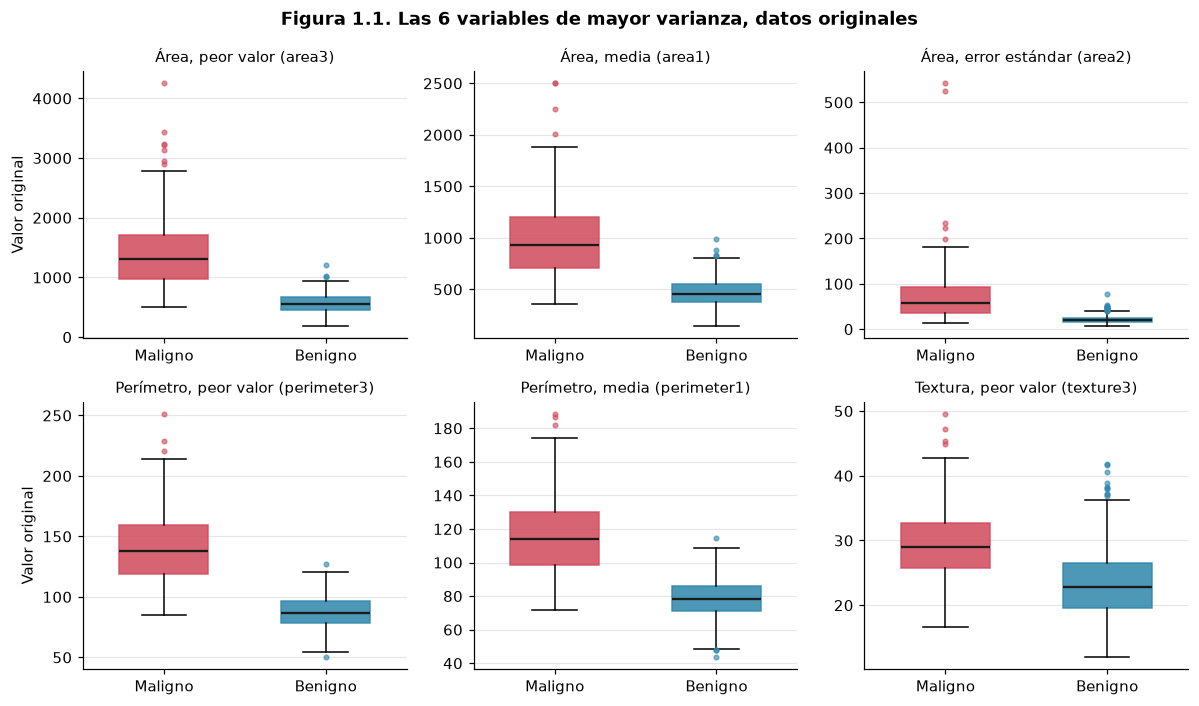

In [8]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Selección de las 6 variables de mayor varianza y sus diagramas de caja.
# Insumo:      X, y.
# Resultado:   top_6, Tabla 1.1 y Figura 1.1.
# ===========================================================
# var() calcula la varianza de cada columna; sort_values las ordena, y ascending=False va de mayor a menor
varianzas = X.var().sort_values(ascending=False)
# head(6) toma las 6 primeras; index son sus nombres; tolist() los convierte en una lista
top_6 = varianzas.head(6).index.tolist()

# X[top_6] conserva solo esas 6 columnas; agg calcula varios estadísticos a la vez.
# .T voltea la tabla (filas por columnas), para tener una variable por fila.
resumen_original = X[top_6].agg(["var", "min", "median", "max"]).T
resumen_original.columns = ["Varianza", "Mínimo", "Mediana", "Máximo"]  # Nombres en español
# Agrega dos columnas: la mediana de esas variables calculada solo con Maligno y solo con Benigno
for clase in COLORES_CLASE:
    resumen_original[f"Mediana {clase}"] = X.loc[y == clase, top_6].median()  # Crea la columna con la mediana de esa clase
print("Tabla 1.1. Las 6 variables originales con mayor varianza")  # Título de la tabla
display(resumen_original.round(2))  # round(2) muestra 2 decimales

# Figura de cajas con los datos originales.
# No se pasa compartir_y, así que vale False: cada panel usa su escala, porque son muy distintas.
graficar_cajas(
    X, top_6, y,  # Datos, variables a dibujar y clases
    "Figura 1.1. Las 6 variables de mayor varianza, datos originales",  # Título
    "Valor original", "figura_1.1_cajas_originales.png",  # Nombre del eje y archivo de la imagen
)  # Cierra la llamada a graficar_cajas

### 1b. Estandarización
`StandardScaler` resta a cada variable su media y la divide entre su desviación estándar, `z = (x - media) / desviación`. Se comprueba que las 30 variables queden con media 0 y desviación 1. `StandardScaler` usa la desviación poblacional (`ddof=0`), así que la comprobación usa la misma.

In [9]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Comprobación de la estandarización de las 30 variables.
# Insumo:      X_std, feature_names.
# Resultado:   X_std_df (X_std con nombres de columna) y Tabla 1.2.
# ===========================================================
# X_std es un arreglo sin nombres de columna; aquí se pasa a tabla para poder usar los nombres
X_std_df = pd.DataFrame(X_std, columns=feature_names)

# Tabla con la media y la desviación estándar de cada variable.
# ddof=0 es la desviación poblacional (divide entre n), la misma que usa StandardScaler.
comprobacion = pd.DataFrame({"Media": X_std_df.mean(), "Desviación estándar": X_std_df.std(ddof=0)})
# allclose comprueba que todos los valores sean casi iguales al indicado; atol es la tolerancia.
# Se usa porque las computadoras redondean: una media puede salir 0.0000000000001 en lugar de 0.
assert np.allclose(comprobacion["Media"], 0, atol=1e-10)  # Todas las medias deben ser 0
assert np.allclose(comprobacion["Desviación estándar"], 1, atol=1e-10)  # Todas las desviaciones deben ser 1

print("Tabla 1.2. Media y desviación estándar de las 30 variables estandarizadas")  # Título
display(comprobacion.round(4) + 0.0)  # Sumar 0.0 convierte -0.0 en 0.0 al mostrar

Tabla 1.2. Media y desviación estándar de las 30 variables estandarizadas


,Media,Desviación estándar
radius1,0.0,1.0
texture1,0.0,1.0
perimeter1,0.0,1.0
area1,0.0,1.0
smoothness1,0.0,1.0
compactness1,0.0,1.0
concavity1,0.0,1.0
concave_points1,0.0,1.0
symmetry1,0.0,1.0
fractal_dimension1,0.0,1.0


### 1c. Las mismas variables, ya estandarizadas
Se usan **las mismas 6 variables del inciso 1a**. Después de estandarizar, las 30 variables tienen la misma varianza, así que ya no se puede volver a elegir por varianza. Conservarlas permite comparar cada variable antes y después. Aquí todos los paneles comparten el eje vertical, porque ya están en la misma escala.

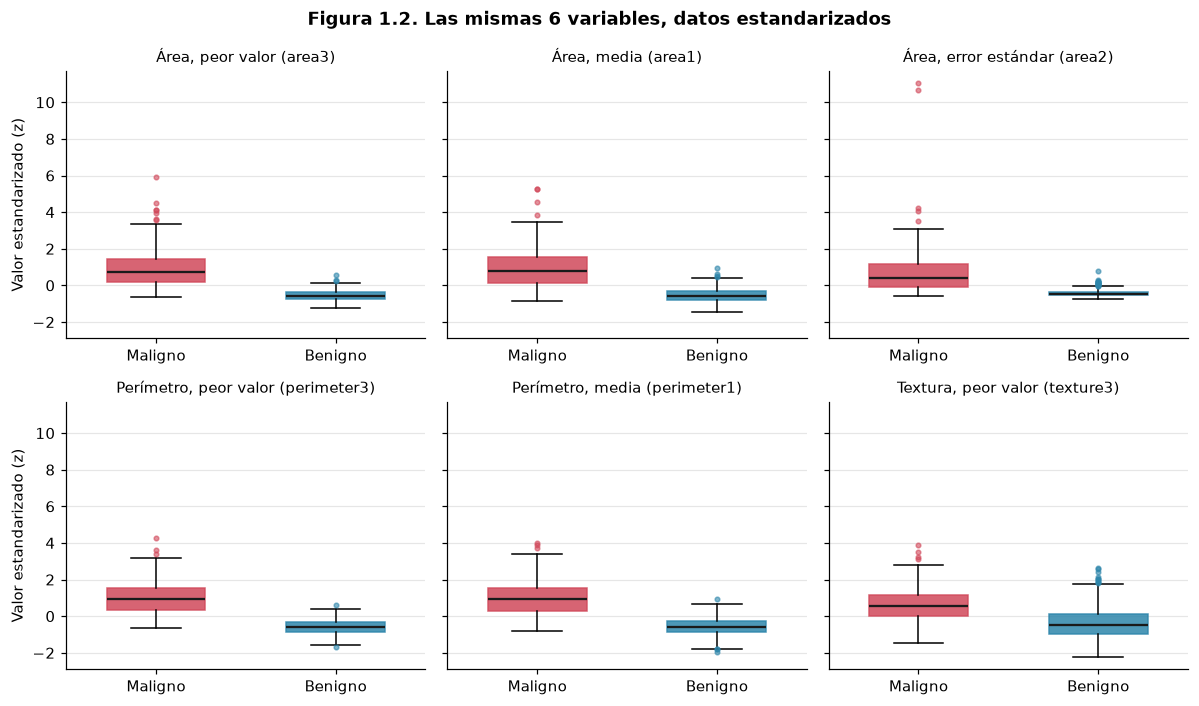

Tabla 1.3. Rango de las 6 variables antes y después de estandarizar


,Rango original,Rango estandarizado,Mínimo estandarizado,Máximo estandarizado
area3,4068.80,7.15,-1.22,5.93
area1,2357.50,6.70,-1.45,5.25
area2,535.40,11.78,-0.74,11.04
perimeter3,200.79,5.98,-1.69,4.29
perimeter1,144.71,5.96,-1.98,3.98
texture3,37.52,6.11,-2.22,3.89


Varianza de area3 entre varianza de la variable con menor varianza (fractal_dimension2): 46,298,438,340 veces
Participación de las 6 variables en la varianza total original: 99.99%


In [10]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Diagramas de caja de las 6 variables estandarizadas y comparación de escalas.
# Insumo:      X_std_df, top_6, y.
# Resultado:   Tabla 1.3 y Figura 1.2.
# ===========================================================
# Misma figura del inciso 1a, con las mismas 6 variables, pero con los datos estandarizados
graficar_cajas(
    X_std_df, top_6, y,  # Ahora usa la tabla estandarizada
    "Figura 1.2. Las mismas 6 variables, datos estandarizados",  # Título
    "Valor estandarizado (z)", "figura_1.2_cajas_estandarizadas.png",  # Nombre del eje y archivo
    compartir_y=True,  # Misma escala en todos los paneles, porque ya son comparables
)  # Cierra la llamada a graficar_cajas

# Compara el rango (máximo menos mínimo) antes y después de estandarizar.
# Cada clave del diccionario es una columna de la tabla.
resumen_escala = pd.DataFrame({
    "Rango original": X[top_6].max() - X[top_6].min(),  # Rango de los datos originales
    "Rango estandarizado": X_std_df[top_6].max() - X_std_df[top_6].min(),  # Rango de los datos estandarizados
    "Mínimo estandarizado": X_std_df[top_6].min(),  # Desviaciones estándar debajo de la media
    "Máximo estandarizado": X_std_df[top_6].max(),  # Desviaciones estándar arriba de la media
})  # Cierra el diccionario y la creación de la tabla
print("Tabla 1.3. Rango de las 6 variables antes y después de estandarizar")  # Título de la tabla
display(resumen_escala.round(2))  # Muestra la tabla con 2 decimales

# Datos para la interpretación del reporte
# iloc toma por posición: iloc[0] es la varianza mayor, e iloc[-1] la menor (la última de la lista).
# ":,.0f" da formato con comas y sin decimales.
print(f"Varianza de area3 entre varianza de la variable con menor varianza ({varianzas.index[-1]}): "
      f"{varianzas.iloc[0] / varianzas.iloc[-1]:,.0f} veces")  # Divide la varianza mayor entre la menor
# Suma de la varianza de las 6 variables entre la de las 30; ":.2%" lo muestra como porcentaje
print(f"Participación de las 6 variables en la varianza total original: {varianzas.head(6).sum() / varianzas.sum():.2%}")

## Sección 2. PCA
**Responsable:** Magaly

**Propósito:** proyectar los datos estandarizados a un espacio de 3 dimensiones con Análisis de Componentes Principales (PCA), medir cuánta información (varianza) conserva cada componente y cómo se relacionan las variables originales con los nuevos ejes.

**Insumo:** `X_std`, `y`, `feature_names`. **Resultado:** `Z_pca3`, `k95`, Tablas 2.1 a 2.2 y Figuras 2.1 a 2.4.

### 2a. Proyección a 3D y tiempo de transformación
PCA busca las direcciones en las que los datos se dispersan más (componentes principales) y proyecta cada observación sobre las 3 primeras. Se mide solo el tiempo de `fit_transform`, que es la transformación.

In [11]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Proyección de los datos estandarizados a 3D con PCA y medición del tiempo.
# Insumo:      X_std, y.
# Resultado:   pca_3d, Z_pca3, t_pca3 y Tabla 2.1.
# ===========================================================
# Prepara PCA para conservar solo 3 componentes; todavía no calcula nada.
# random_state fija la semilla por si sklearn usa un método aleatorio internamente.
pca_3d = PCA(n_components=3, random_state=SEED)

# --- MEDICIÓN DEL TIEMPO ---
# perf_counter() da la hora del cronómetro; la diferencia entre dos lecturas es el tiempo transcurrido.
# Solo se mide la transformación, no la impresión ni las gráficas (README, sección 3.4).
t0 = perf_counter()                      # Inicio del cronómetro
Z_pca3 = pca_3d.fit_transform(X_std)     # fit calcula los componentes y transform proyecta los datos
t_pca3 = perf_counter() - t0             # Tiempo total en segundos

# ":.4f" muestra 4 decimales
print(f"Tiempo de transformación con PCA a 3D: {t_pca3:.4f} s")
# shape da (filas, columnas): deben seguir siendo 569 observaciones, ahora con 3 columnas
print(f"Dimensiones antes: {X_std.shape} -> después: {Z_pca3.shape}")

# Registra el tiempo en la tabla comparativa del inciso 5a
comparativa.loc["PCA", "tiempo_s"] = round(t_pca3, 4)

# Tabla con las primeras 5 observaciones ya proyectadas, como evidencia de la transformación.
# Se agrega la clase para ver a qué diagnóstico corresponde cada punto.
tabla_pca3 = pd.DataFrame(Z_pca3, columns=["PC1", "PC2", "PC3"])  # Convierte el arreglo en tabla
tabla_pca3["Clase"] = y.values                                     # values da las etiquetas sin índice
print("Tabla 2.1. Primeras 5 observaciones en el espacio PCA de 3 dimensiones")  # Título
display(tabla_pca3.head().round(4))                                # head() muestra las primeras 5 filas

Tiempo de transformación con PCA a 3D: 0.0094 s
Dimensiones antes: (569, 30) -> después: (569, 3)
Tabla 2.1. Primeras 5 observaciones en el espacio PCA de 3 dimensiones


,PC1,PC2,PC3,Clase
0,9.1928,1.9486,-1.1232,Maligno
1,2.3878,-3.7682,-0.5293,Maligno
2,5.7339,-1.0752,-0.5517,Maligno
3,7.1230,10.2756,-3.2328,Maligno
4,3.9353,-1.9481,1.3898,Maligno


### 2b. Varianza explicada y acumulada por componente
Se ajusta PCA con las 30 componentes para conocer qué porcentaje de la varianza total explica cada una y cuánto se acumula al sumarlas. Se reportan las 10 primeras y se identifica cuántas se necesitan para conservar al menos 95% de la varianza (`k95`), valor que usa la Sección 3.

In [12]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Varianza explicada y acumulada de los componentes principales y cálculo de k95.
# Insumo:      X_std.
# Resultado:   pca_todas, var_exp, var_acum, k95, Tabla 2.2 y resultados/pca_varianza.csv.
# ===========================================================
# Sin n_components, PCA calcula las 30 componentes posibles (una por variable).
# Se necesitan todas para que la varianza acumulada sea correcta (README, advertencias de PCA).
pca_todas = PCA(random_state=SEED)  # Nombre distinto a pca_completo, que ya se usó en la Sección 0
pca_todas.fit(X_std)                # Solo calcula los componentes; aquí no se necesita proyectar

# explained_variance_ratio_ da la fracción de la varianza total que explica cada componente.
# Multiplicar por 100 la convierte en porcentaje.
var_exp = pca_todas.explained_variance_ratio_ * 100
# cumsum es la suma acumulada: PC1, PC1+PC2, PC1+PC2+PC3, etc.
var_acum = np.cumsum(var_exp)

# Tabla con los 10 primeros componentes; [:10] toma los elementos de la posición 0 a la 9
tabla_varianza = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, 11)],         # Nombres PC1 a PC10; range(1, 11) va de 1 a 10
    "Varianza explicada (%)": var_exp[:10],          # Porcentaje de cada componente
    "Varianza acumulada (%)": var_acum[:10],         # Porcentaje acumulado hasta ese componente
})  # Cierra la creación de la tabla
print("Tabla 2.2. Varianza explicada y acumulada de los 10 primeros componentes principales")  # Título
display(tabla_varianza.round(2))  # Muestra con 2 decimales

# --- k95 ---
# var_acum >= 95 da una lista de True/False; argmax da la posición del primer True.
# Se suma 1 porque Python cuenta las posiciones desde 0, pero los componentes desde 1.
k95 = int(np.argmax(var_acum >= 95) + 1)
print(f"k95 = {k95}: los primeros {k95} componentes acumulan {var_acum[k95 - 1]:.2f}% de la varianza")
# Dato para la interpretación: cuánta información conserva la proyección a 3D del inciso 2a
print(f"Las 3 primeras componentes conservan {var_acum[2]:.2f}% de la varianza")

# Exporta la tabla para el tablero (README, sección 3.8); round(4) guarda 4 decimales
exportar_csv(tabla_varianza.round(4), "pca_varianza.csv")

Tabla 2.2. Varianza explicada y acumulada de los 10 primeros componentes principales


,PC,Varianza explicada (%),Varianza acumulada (%)
0,PC1,44.27,44.27
1,PC2,18.97,63.24
2,PC3,9.39,72.64
3,PC4,6.60,79.24
4,PC5,5.50,84.73
5,PC6,4.02,88.76
6,PC7,2.25,91.01
7,PC8,1.59,92.60
8,PC9,1.39,93.99
9,PC10,1.17,95.16


k95 = 10: los primeros 10 componentes acumulan 95.16% de la varianza
Las 3 primeras componentes conservan 72.64% de la varianza


### 2c. Gráfica de varianza explicada y acumulada
Las barras muestran la varianza que explica cada componente y la línea, la varianza acumulada. Se marca el umbral de 95% y el valor `k95`. Las tres primeras barras se resaltan porque corresponden a la proyección 3D del inciso 2a. Ambas series están en porcentaje, por lo que comparten un solo eje vertical.

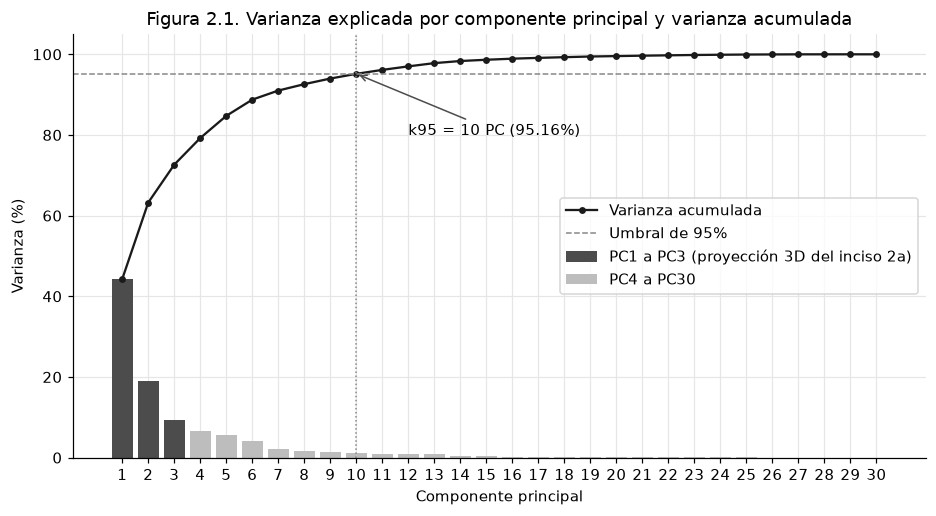

In [13]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Gráfica de barras de varianza explicada con línea de varianza acumulada.
# Insumo:      var_exp, var_acum, k95.
# Resultado:   Figura 2.1 (figuras/figura_2.1_varianza_pca.png).
# ===========================================================
# arange(1, 31) crea los números 1, 2, ..., 30: la posición de cada componente en el eje x
num_pc = np.arange(1, len(var_exp) + 1)

fig, ax = plt.subplots(figsize=(10, 5))  # Figura de 10 x 5 pulgadas con un solo panel (ax)

# --- BARRAS ---
# Se dibujan en dos grupos para distinguirlos: [:3] son PC1 a PC3 y [3:] son PC4 a PC30.
# Las 3 primeras usan el color fijo de PCA; el resto, un gris claro para que no compitan.
ax.bar(num_pc[:3], var_exp[:3], color=COLORES_METODO["PCA"], label="PC1 a PC3 (proyección 3D del inciso 2a)")
ax.bar(num_pc[3:], var_exp[3:], color="#BDBDBD", label="PC4 a PC30")

# --- LÍNEA DE VARIANZA ACUMULADA ---
# marker="o" pone un punto en cada componente; linewidth es el grosor de la línea
ax.plot(num_pc, var_acum, color="#1A1A1A", marker="o", markersize=3.5, linewidth=1.5,
        label="Varianza acumulada")

# --- UMBRAL DE 95% Y k95 ---
# axhline dibuja una línea horizontal en y = 95; axvline, una vertical en x = k95
ax.axhline(95, color="#888888", linestyle="--", linewidth=1, label="Umbral de 95%")
ax.axvline(k95, color="#888888", linestyle=":", linewidth=1)
# annotate escribe un texto con una flecha: xy es a dónde apunta y xytext dónde va el texto
ax.annotate(f"k95 = {k95} PC ({var_acum[k95 - 1]:.2f}%)",
            xy=(k95, var_acum[k95 - 1]), xytext=(k95 + 2, 80),
            arrowprops={"arrowstyle": "->", "color": "#4C4C4C"})

# --- EJES Y TEXTOS ---
ax.set_xticks(num_pc)                      # Muestra un número por cada componente (1 a 30)
ax.set_xlabel("Componente principal")      # Nombre del eje x
ax.set_ylabel("Varianza (%)")              # Nombre del eje y; las dos series están en porcentaje
ax.set_ylim(0, 105)                        # El eje y va de 0 a 105 para que se vea el 100%
ax.set_title("Figura 2.1. Varianza explicada por componente principal y varianza acumulada")
ax.legend(loc="center right")              # Leyenda a la derecha, donde las barras ya son bajas

fig.savefig(RUTA_FIGURAS / "figura_2.1_varianza_pca.png")  # Guarda la imagen para el reporte
plt.show()                                                  # Muestra la figura en el notebook

### 2d. Círculo de correlaciones
Cada flecha representa una variable original y sus coordenadas son su correlación con dos componentes principales. Una flecha cercana al borde del círculo indica que la variable está bien representada en ese plano, y flechas que apuntan en la misma dirección indican variables correlacionadas entre sí. Se grafican PC1 contra PC2 y PC1 contra PC3. Para que el texto sea legible, solo se etiquetan las 6 flechas más largas con direcciones distintas; los 30 valores están en la Tabla 2.3.

Tabla 2.3. Correlación de las 30 variables con los 3 primeros componentes principales


,PC1,PC2,PC3
radius1,0.80,-0.56,-0.01
texture1,0.38,-0.14,0.11
perimeter1,0.83,-0.51,-0.02
area1,0.81,-0.55,0.05
smoothness1,0.52,0.44,-0.18
compactness1,0.87,0.36,-0.12
concavity1,0.94,0.14,0.00
concave_points1,0.95,-0.08,-0.04
symmetry1,0.50,0.45,-0.07
fractal_dimension1,0.23,0.87,-0.04


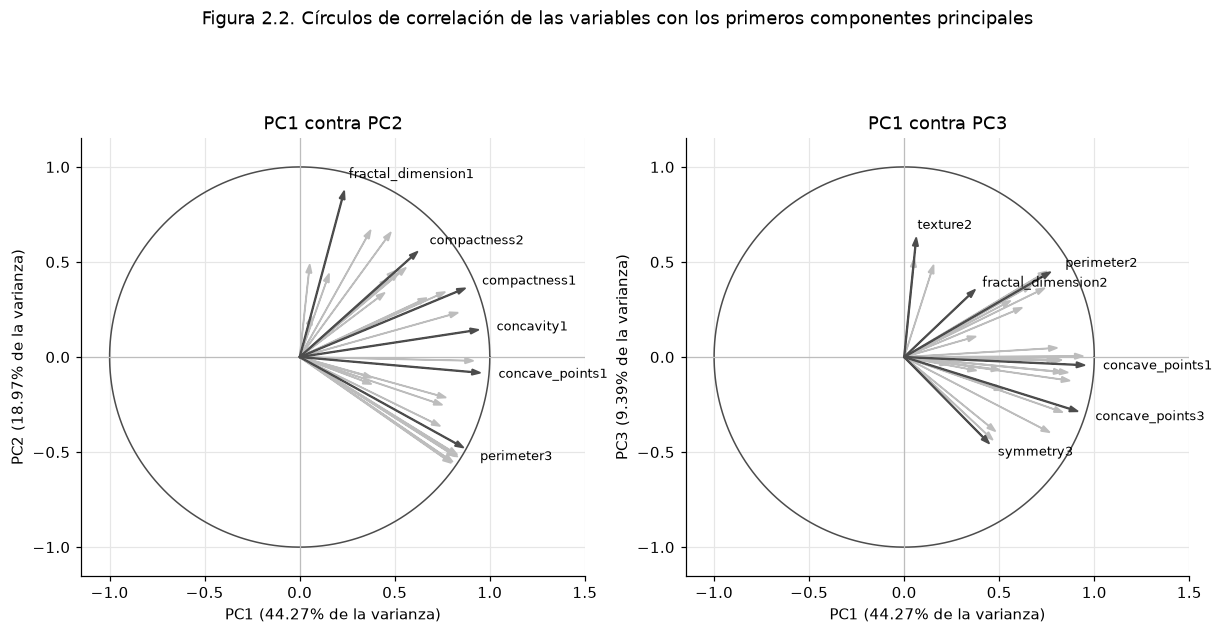

In [14]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Correlación de cada variable con los 3 primeros PC y círculos de correlación.
# Insumo:      X_std, Z_pca3, feature_names, var_exp.
# Resultado:   correlaciones, Tabla 2.3 y Figura 2.2 (figuras/figura_2.2_circulo_correlaciones.png).
# ===========================================================
# --- CORRELACIONES ---
# Correlación de Pearson entre cada variable original (estandarizada) y cada componente.
# Va de -1 a 1: cerca de 1, la variable crece cuando el PC crece; cerca de -1, crece cuando el PC baja.
nombres_pc = ["PC1", "PC2", "PC3"]
# Tabla vacía: una fila por variable y una columna por PC; se llena con el ciclo de abajo
correlaciones = pd.DataFrame(index=feature_names, columns=nombres_pc, dtype=float)
for j, variable in enumerate(feature_names):   # enumerate da la posición (j) y el nombre de cada variable
    for i, pc in enumerate(nombres_pc):         # Recorre PC1, PC2 y PC3
        # corrcoef regresa una matriz de 2 x 2; el valor [0, 1] es la correlación entre las dos series
        correlaciones.loc[variable, pc] = np.corrcoef(X_std[:, j], Z_pca3[:, i])[0, 1]

print("Tabla 2.3. Correlación de las 30 variables con los 3 primeros componentes principales")
display(correlaciones.round(2))  # Evidencia completa: incluye las variables sin etiqueta en la figura


def graficar_circulo(ax, pc_x, pc_y):  # Recibe el panel y los nombres de los dos PC a comparar
    """Dibuja el círculo de correlación de las 30 variables para dos componentes."""
    x = correlaciones[pc_x].values  # Correlación de cada variable con el PC del eje x
    y_ = correlaciones[pc_y].values  # Con el PC del eje y (y_ para no confundir con las clases y)

    # Círculo unitario: ninguna flecha puede salir de él, porque una correlación no pasa de 1
    angulos = np.linspace(0, 2 * np.pi, 200)  # 200 ángulos de 0 a 360 grados (en radianes)
    ax.plot(np.cos(angulos), np.sin(angulos), color=COLORES_METODO["PCA"], linewidth=1)
    ax.axhline(0, color="#BDBDBD", linewidth=0.8)  # Eje horizontal en 0
    ax.axvline(0, color="#BDBDBD", linewidth=0.8)  # Eje vertical en 0

    # --- VARIABLES QUE SE ETIQUETAN ---
    # 30 nombres se enciman, así que solo se etiquetan 6: las flechas más largas
    # (mejor representadas en este plano) que apunten en direcciones distintas.
    largo = np.hypot(x, y_)                     # Largo de cada flecha: raíz de (x² + y²)
    angulo = np.degrees(np.arctan2(y_, x))      # Dirección de cada flecha en grados
    etiquetadas = []                            # Aquí se guardan las posiciones elegidas
    for j in np.argsort(largo)[::-1]:           # argsort ordena de menor a mayor; [::-1] lo invierte
        # Se elige solo si su dirección se separa al menos 12 grados de las ya elegidas
        if all(abs(angulo[j] - angulo[k]) >= 12 for k in etiquetadas):
            etiquetadas.append(j)
        if len(etiquetadas) == 6:               # Al llegar a 6 se detiene
            break

    # --- FLECHAS ---
    for j in range(len(feature_names)):         # Una flecha por variable, desde el origen (0, 0)
        destacada = j in etiquetadas            # True si esta variable lleva etiqueta
        ax.arrow(0, 0, x[j], y_[j], length_includes_head=True, head_width=0.03,
                 width=0.004 if destacada else 0.002,                       # Más gruesa si se etiqueta
                 color=COLORES_METODO["PCA"] if destacada else "#BDBDBD",  # Oscura o gris claro
                 zorder=3 if destacada else 2)                              # zorder: las oscuras van encima
    for j in etiquetadas:  # El texto va un poco más allá de la punta (1.1 veces)
        ax.text(x[j] * 1.1, y_[j] * 1.1, feature_names[j], fontsize=8.5, va="center",
                ha="left" if x[j] >= 0 else "right")  # Alinea el texto hacia afuera del círculo

    # --- EJES ---
    ax.set_xlim(-1.15, 1.5)   # Espacio extra a la derecha para los nombres
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect("equal")    # Misma escala en x y y, para que el círculo no se vea ovalado
    # El porcentaje de varianza de cada PC indica cuánto pesa ese eje
    ax.set_xlabel(f"{pc_x} ({var_exp[nombres_pc.index(pc_x)]:.2f}% de la varianza)")
    ax.set_ylabel(f"{pc_y} ({var_exp[nombres_pc.index(pc_y)]:.2f}% de la varianza)")
    ax.set_title(f"{pc_x} contra {pc_y}")


# Dos paneles lado a lado: PC1 contra PC2 y PC1 contra PC3
fig, (ax_izq, ax_der) = plt.subplots(1, 2, figsize=(13, 6.5))
graficar_circulo(ax_izq, "PC1", "PC2")
graficar_circulo(ax_der, "PC1", "PC3")
fig.suptitle("Figura 2.2. Círculos de correlación de las variables con los primeros componentes principales")
fig.savefig(RUTA_FIGURAS / "figura_2.2_circulo_correlaciones.png")  # Guarda la imagen para el reporte
plt.show()

### 2e. Espacio de 3 dimensiones de PCA
Se grafican las 569 observaciones en el espacio formado por PC1, PC2 y PC3, con un color por clase: rojo para maligno y azul para benigno.

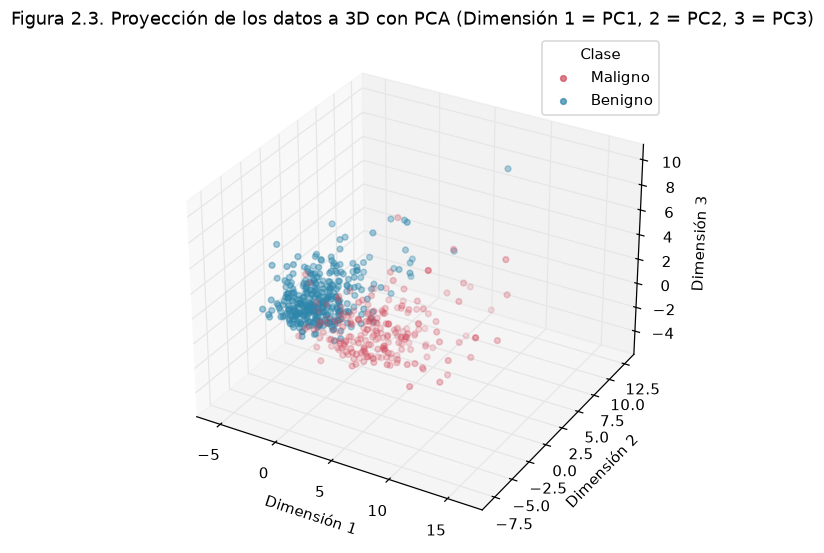

In [15]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Dispersión 3D de la proyección PCA, con un color por clase.
# Insumo:      Z_pca3, y.
# Resultado:   Figura 2.3 (figuras/figura_2.3.png).
# ===========================================================
# graficar_3d es la función compartida de la Sección 0: usa COLORES_CLASE y guarda la imagen.
# Recibe la proyección, las clases, el título y el número de figura.
# En esta figura, Dimensión 1, 2 y 3 corresponden a PC1, PC2 y PC3.
graficar_3d(Z_pca3, y, "Proyección de los datos a 3D con PCA (Dimensión 1 = PC1, 2 = PC2, 3 = PC3)", "2.3")

### 2f. Error de reconstrucción contra el número de componentes
Para cada k de 1 a 30 se proyectan los datos a k componentes y se reconstruyen en el espacio original de 30 variables con `inverse_transform`. El error de reconstrucción es el error cuadrático medio (MSE) entre los datos estandarizados y su reconstrucción. Se marcan k = 3, usado en la proyección 3D, y `k95`.

Tabla 2.4. Error de reconstrucción de PCA para valores representativos de k


,k,MSE
0,1,0.5573
1,2,0.3676
2,3,0.2736
4,5,0.1527
9,10,0.0484
19,20,0.0044
29,30,0.0000


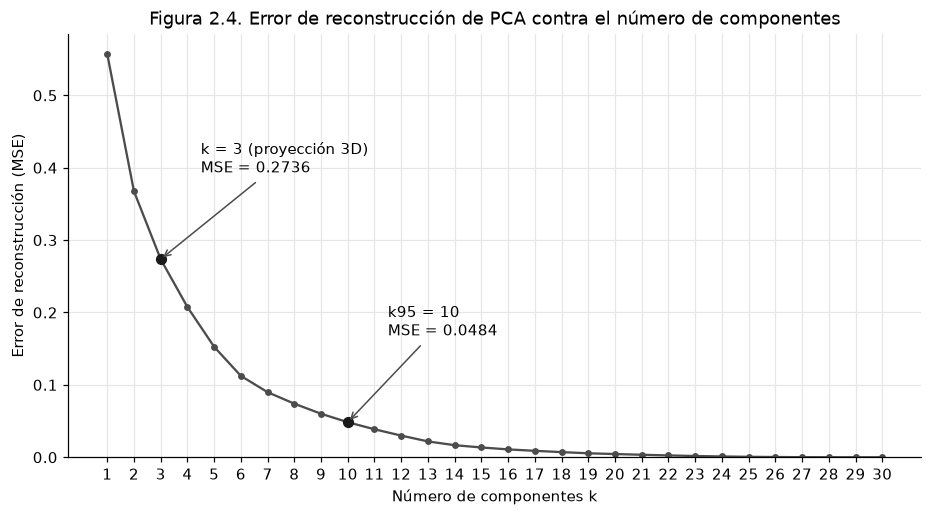

In [16]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Error de reconstrucción (MSE) de PCA contra el número de componentes k.
# Insumo:      X_std, k95.
# Resultado:   tabla_error_rec, Tabla 2.4, Figura 2.4 y resultados/pca_error_reconstruccion.csv.
# ===========================================================
# Para cada k de 1 a 30: se proyecta a k dimensiones, se regresa a las 30 variables
# (inverse_transform) y se mide cuánto se alejó la reconstrucción de los datos reales.
filas = []                                  # Aquí se guarda un par (k, MSE) por cada k
for k in range(1, X_std.shape[1] + 1):      # range(1, 31) recorre k = 1, 2, ..., 30
    pca_k = PCA(n_components=k, random_state=SEED)       # PCA que conserva k componentes
    Z_k = pca_k.fit_transform(X_std)                     # Proyección a k dimensiones
    X_rec = pca_k.inverse_transform(Z_k)                 # Regreso al espacio de 30 variables
    # error_reconstruccion es la función compartida de la Sección 0 (MSE)
    filas.append({"k": k, "MSE": error_reconstruccion(X_std, X_rec)})
tabla_error_rec = pd.DataFrame(filas)       # Convierte la lista en tabla: columnas k y MSE

# Tabla con algunos valores representativos, como evidencia
print("Tabla 2.4. Error de reconstrucción de PCA para valores representativos de k")
# isin conserva solo las filas cuyo k esté en la lista
display(tabla_error_rec[tabla_error_rec["k"].isin([1, 2, 3, 5, 10, 20, 30])].round(4))

# --- GRÁFICA ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tabla_error_rec["k"], tabla_error_rec["MSE"], color=COLORES_METODO["PCA"],
        marker="o", markersize=3.5, linewidth=1.5)
# Marca los dos valores de k que se usan en la práctica: 3 (proyección 3D) y k95
for k_marcado, texto in [(3, "k = 3 (proyección 3D)"), (k95, f"k95 = {k95}")]:
    # Busca la fila de ese k y toma su MSE; iloc[0] saca el único valor encontrado
    mse_k = tabla_error_rec.loc[tabla_error_rec["k"] == k_marcado, "MSE"].iloc[0]
    ax.scatter(k_marcado, mse_k, color="#1A1A1A", s=40, zorder=3)  # Punto más grande y oscuro
    # "\n" es un salto de línea dentro del texto
    ax.annotate(f"{texto}\nMSE = {mse_k:.4f}", xy=(k_marcado, mse_k),
                xytext=(k_marcado + 1.5, mse_k + 0.12),       # El texto va arriba a la derecha
                arrowprops={"arrowstyle": "->", "color": "#4C4C4C"})
ax.set_xticks(tabla_error_rec["k"])          # Un número por cada k
ax.set_xlabel("Número de componentes k")
ax.set_ylabel("Error de reconstrucción (MSE)")
ax.set_ylim(bottom=0)                        # El eje empieza en 0, el error mínimo posible
ax.set_title("Figura 2.4. Error de reconstrucción de PCA contra el número de componentes")
fig.savefig(RUTA_FIGURAS / "figura_2.4_error_reconstruccion_pca.png")
plt.show()

# Exporta la curva completa para el tablero (README, sección 3.8)
exportar_csv(tabla_error_rec, "pca_error_reconstruccion.csv")

### Métricas de PCA para la tabla comparativa (inciso 5a)
Se calculan sobre la proyección 3D del inciso 2a, con las funciones compartidas de la Sección 0 para que sean comparables con los demás métodos: stress de Sammon respecto a `X_std` (30 dimensiones), exactitud de k-NN y error de reconstrucción con k = 3. Se exporta además la proyección 3D para el tablero.

In [17]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Métricas de la proyección PCA 3D para la tabla 5a y exportación de resultados.
# Insumo:      X_std, Z_pca3, y, t_pca3, tabla_error_rec.
# Resultado:   Tabla 2.5, fila PCA de comparativa y resultados/pca_3d.csv.
# ===========================================================
# Stress de Sammon: cuánto se deformaron las distancias entre pacientes al pasar de 30D a 3D
stress_pca3 = stress_sammon(X_std, Z_pca3)
# k-NN: qué tan bien se distinguen las clases en el espacio 3D (media y desviación de 5 particiones)
knn_media_pca3, knn_std_pca3 = evaluar_knn(Z_pca3, y)
# Error de reconstrucción con k = 3, ya calculado en el inciso 2f; se toma de la tabla
mse_pca3 = tabla_error_rec.loc[tabla_error_rec["k"] == 3, "MSE"].iloc[0]

# --- REGISTRO EN LA TABLA COMPARATIVA ---
# .loc[fila, columna] = valor; round(4) deja 4 decimales, como acordó el equipo
comparativa.loc["PCA", "stress_sammon"] = round(stress_pca3, 4)
comparativa.loc["PCA", "knn_exactitud_media"] = round(knn_media_pca3, 4)
comparativa.loc["PCA", "knn_exactitud_std"] = round(knn_std_pca3, 4)
comparativa.loc["PCA", "error_reconstruccion_mse"] = round(mse_pca3, 4)
comparativa.loc["PCA", "notas"] = "3 componentes; stress contra X_std (30D); MSE en el espacio estandarizado"

# Tabla de evidencia con las 4 métricas de PCA
metricas_pca = pd.DataFrame({
    "Métrica": ["Tiempo de transformación (s)", "Stress de Sammon (contra X_std)",
                "Exactitud k-NN (media)", "Exactitud k-NN (desviación)", "Error de reconstrucción (MSE)"],
    "Valor": [t_pca3, stress_pca3, knn_media_pca3, knn_std_pca3, mse_pca3],
})  # Cierra la creación de la tabla
print("Tabla 2.5. Métricas de la proyección PCA a 3 dimensiones")
display(metricas_pca.round(4))

# --- EXPORTACIÓN ---
# Proyección 3D con la clase de cada punto, para graficarla en el tablero
exportar_csv(tabla_pca3, "pca_3d.csv")  # tabla_pca3 se creó en el inciso 2a (PC1, PC2, PC3, Clase)

Tabla 2.5. Métricas de la proyección PCA a 3 dimensiones


,Métrica,Valor
0,Tiempo de transformación (s),0.0094
1,Stress de Sammon (contra X_std),0.0593
2,Exactitud k-NN (media),0.9332
3,Exactitud k-NN (desviación),0.0226
4,Error de reconstrucción (MSE),0.2736


## Sección 3. Sammon
### Incisos 3a a 3f
**Responsable:** Ricardo

_Pendiente: Sammon adaptado (con historial de stress), `pca_mas_sammon(X_std, k)` e incisos 3a a 3f. Las celdas de 3g a 3i usan estos nombres:_

- _`pca_mas_sammon(X_std, k)` regresa un diccionario con `t_pca`, `t_sammon`, `t_total`, `Z`, `stress_libreria` y `stress_xstd`._
- _`Z_sammon`: proyección 3D del inciso 3a._
- _`t_sammon_directo`: tiempo total del inciso 3a._
- _`stress_libreria_directo`: stress final que devuelve la librería en el inciso 3a._

### Incisos 3g a 3i. Barrido de k
**Responsable:** Melanie

_Pendiente: se agregan cuando estén los incisos 3a a 3f._

## Sección 4. Autocodificador
**Responsable:** Santiago

_Pendiente: inciso 4a. Antes de ejecutar, fijar la semilla con `tf.keras.utils.set_random_seed(SEED)`._

## Sección 5. Análisis y conclusiones
**Responsable:** Santiago

_Pendiente: incisos 5a y 5b. Completar `comparativa` y volver a exportarla con `exportar_csv(comparativa.reset_index(), "comparativa.csv")`._

## Sección 6. Tablero de resultados
**Responsable:** Magaly

_Pendiente: incisos 6a a 6d._